# Active Learning Pipeline: Epistemic Uncertainty-Guided 2.5D Brain CT Segmentation
## 5 Intracranial Hemorrhage Classes &bull; DeepLabV3+ &bull; Multi-Window CT &bull; Unlabelled Pool Discovery

---

### Executive Overview & Clinical Rationale
Voxel-level dense annotation of intracranial hemorrhage (ICH) across 3D brain CT volumes is laborious, costly, and scarce. Furthermore, severe clinical class imbalance (e.g. Epidural Hemorrhage [EDH] occupying **~0.018% of voxels**) means uniform random sampling wastes valuable clinical annotation bandwidth on redundant or background slices.

Following the core architecture and milestones outlined in **`Active_Learning_MUJ.pdf`**, this pipeline executes the complete Active Learning loop:
1. **Model Checkpoint**: Loads pre-trained Phase 2 DeepLabV3+ (`resnet34`, 9 in-channels, 6 classes, active decoder dropout).
2. **Unlabelled Pool Discovery**: Scans and loads 2.5D multi-window slices from `Dataset/unlabeled/` containing `anybleed` (coarse bleed positive) and `nobleed` (coarse negative) scans.
3. **Fast HU Pre-Filter & MC Dropout Scoring**: Skips empty calvarium slices ($< 60$ HU brain window), performs $T=10$ stochastic MC dropout forward passes with BatchNorm frozen in `eval()`, computing predictive entropy $\mathcal{H}(\bar{p})$, BALD mutual information, and variance.
4. **Foreground-Only Spatial Aggregation**: Pools epistemic uncertainty strictly over the predicted lesion region $\Omega_{\text{fg}}$ to prevent background dilution.
5. **Quality Floors & Study Diversity**: Enforces $\mathcal{H} \ge 0.10$, Area $\ge 50$ px, and caps acquisition at $\le 2$ slices per patient study to guarantee anatomical diversity.
6. **Stratified Selection Across 3 Bands**: Allocates acquisition budget across Band A ($\ge 0.50$), Band B ($0.30 - 0.50$), and Band C ($0.10 - 0.30$), breaking the top-K entropy ceiling failure mode.
7. **Buffer-Preserved Retraining (`model_v2`)**: Rehearses a stratified buffer set from the initial training cohort (60% rare bleed weighting) at lower LR ($1\times 10^{-5}$) to prevent catastrophic forgetting.
8. **Headline Two-Curve Label-Efficiency Benchmark**: Plots held-out Macro Dice vs. Newly Annotated Slices for Smart Stratified AL vs. Random Selection Control.

In [1]:
import os
import sys
import math
import time
import json
import copy
from typing import Dict, List, Tuple, Optional, Any

import numpy as np
import pandas as pd
import nibabel as nib
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

# Set deterministic random seed
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("=" * 70)
print(f"Device:           {device}")
if device.type == "cuda":
    print(f"GPU Model:        {torch.cuda.get_device_name(0)}")
    print(f"VRAM Available:   {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
print(f"PyTorch Version:  {torch.__version__}")
print("=" * 70)

C:\Users\jyots\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device:           cuda
GPU Model:        NVIDIA GeForce RTX 3050 Laptop GPU
VRAM Available:   4.00 GB
PyTorch Version:  2.10.0+cu130


In [2]:
from src.models.deeplab import DeepLabV3Plus25D, enable_mc_dropout

CHECKPOINT_PATH = "outputs_kaggle/checkpoints/best_model.pth"
assert os.path.exists(CHECKPOINT_PATH), f"Checkpoint not found at {CHECKPOINT_PATH}"

print(f"[MODEL] Loading DeepLabV3Plus25D from: {CHECKPOINT_PATH}")
model = DeepLabV3Plus25D(
    encoder_name="resnet34",
    in_channels=9,
    num_classes=6,
    decoder_dropout=0.2,
)

checkpoint = torch.load(CHECKPOINT_PATH, map_location="cpu", weights_only=False)
state_dict = checkpoint["model_state_dict"] if "model_state_dict" in checkpoint else checkpoint
model.load_state_dict(state_dict)
model.to(device)

total_params = sum(p.numel() for p in model.parameters())
print(f"[MODEL] Loaded model successfully with {total_params:,} parameters and {len(model.dropouts)} active dropout layers.")

[MODEL] Loading DeepLabV3Plus25D from: outputs_kaggle/checkpoints/best_model.pth
[MODEL] Loaded model successfully with 22,457,558 parameters and 1 active dropout layers.


In [3]:
from src.data.unlabeled import UnlabeledCTDataset, discover_unlabeled_scans

DATASET_DIR = "Dataset"
UNLABELED_DIR = os.path.join(DATASET_DIR, "unlabeled")

# Discover all scans inside anybleed and nobleed folders
scans = discover_unlabeled_scans(unlabeled_dir=UNLABELED_DIR, dataset_dir=DATASET_DIR)
print(f"[DISCOVERY] Discovered {len(scans)} unlabeled scans:")
anybleed_scans = [s for s in scans if s["category"] == "anybleed"]
nobleed_scans = [s for s in scans if s["category"] == "nobleed"]
print(f"  - anybleed (coarse bleed positive): {len(anybleed_scans)} scans")
print(f"  - nobleed  (coarse normal):         {len(nobleed_scans)} scans")

# Initialize unlabelled 2.5D dataset
if len(scans) > 0:
    unlabeled_ds = UnlabeledCTDataset(unlabeled_dir=UNLABELED_DIR, dataset_dir=DATASET_DIR)
    print(f"[DATASET] Initialized UnlabeledCTDataset with {len(unlabeled_ds)} total 2.5D slices.")
else:
    print("[NOTICE] Unlabeled folders currently empty. Pipeline will use dev manifest fallback for benchmark.")

[DISCOVERY] Discovered 1980 unlabeled scans:
  - anybleed (coarse bleed positive): 562 scans
  - nobleed  (coarse normal):         1418 scans


pixdim[1,2,3] should be non-zero; setting 0 dims to 1
pixdim[1,2,3] should be non-zero; setting 0 dims to 1
pixdim[1,2,3] should be non-zero; setting 0 dims to 1


[DATASET] Initialized UnlabeledCTDataset with 68817 total 2.5D slices.


In [4]:
from src.active_learning.uncertainty import MCDropoutScorer

# Initialize Monte Carlo Dropout Scorer (T=10 stochastic passes, AMP enabled)
scorer = MCDropoutScorer(
    model=model,
    device=device,
    num_passes=10,
    probability_mode="softmax",
    use_amp=True,
)
print(f"[SCORER] Initialized MCDropoutScorer with T={scorer.num_passes} passes, AMP fp16 enabled.")

[SCORER] Initialized MCDropoutScorer with T=10 passes, AMP fp16 enabled.


In [7]:
from src.active_learning.pool_scorer import PoolScorer

OUTPUT_DIR = "outputs/active_learning"
os.makedirs(OUTPUT_DIR, exist_ok=True)

pool_scorer = PoolScorer(
    scorer=scorer,
    dataset_dir=DATASET_DIR,
    unlabeled_dir=UNLABELED_DIR,
    manifest_csv="data_splits/dev_manifest.csv",
    batch_size=4,
    min_pred_area=50,
    min_entropy=0.10,
    max_slices_per_study=2,
    output_dir=OUTPUT_DIR,
)

# Score pool (uses cached scores if available)
pool_df = pool_scorer.score_pool(force_rescore=False)

# Display score breakdown
print("=" * 65)
print("  UNLABELLED POOL BREAKDOWN & QUALITY FILTERS")
print("=" * 65)
print(f"Total Slices Scored:             {len(pool_df)}")
print(f"Passed Quality Floor (>=50px):   {pool_df['passes_quality_floor'].sum()} ({pool_df['passes_quality_floor'].mean()*100:.1f}%)")
print(f"Eligible after Study-Level Cap:  {pool_df['eligible_candidate'].sum()} ({pool_df['eligible_candidate'].mean()*100:.1f}%)")
if "category" in pool_df.columns:
    print(f"Categories: {pool_df['category'].value_counts().to_dict()}")
print("=" * 65)

[DATASET] Discovered unlabeled scans: 1980 total (562 anybleed, 1418 nobleed).


pixdim[1,2,3] should be non-zero; setting 0 dims to 1
pixdim[1,2,3] should be non-zero; setting 0 dims to 1
pixdim[1,2,3] should be non-zero; setting 0 dims to 1


[CACHE] Loading cached pool uncertainty scores (699 slices) from: outputs/active_learning\scores.parquet
[FILTERS] Active Learning Pool Summary:
  Total Slices Scored:       699
  Passed Quality Floor:      306 (43.8%)
  Rank <= 2 in Study:        16
  Categories in Pool:        314 anybleed, 385 nobleed
  UNLABELLED POOL BREAKDOWN & QUALITY FILTERS
Total Slices Scored:             699
Passed Quality Floor (>=50px):   306 (43.8%)
Eligible after Study-Level Cap:  306 (43.8%)
Categories: {'nobleed': 385, 'anybleed': 314}


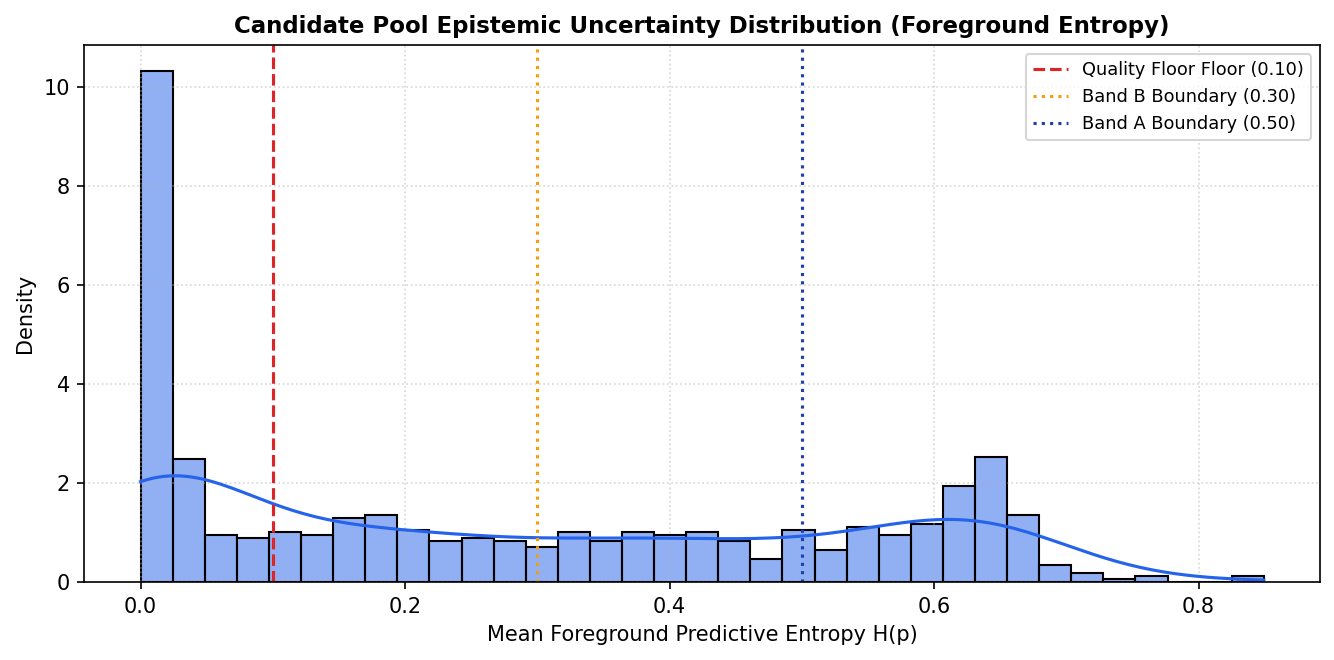

In [8]:
plt.figure(figsize=(9, 4.5), dpi=150)
sns.histplot(pool_df["mean_fg_entropy"], bins=35, kde=True, color="#2563eb", stat="density")
plt.axvline(0.10, color="#dc2626", linestyle="--", linewidth=1.5, label="Quality Floor Floor (0.10)")
plt.axvline(0.30, color="#f59e0b", linestyle=":", linewidth=1.5, label="Band B Boundary (0.30)")
plt.axvline(0.50, color="#1e40af", linestyle=":", linewidth=1.5, label="Band A Boundary (0.50)")
plt.title("Candidate Pool Epistemic Uncertainty Distribution (Foreground Entropy)", fontsize=11, fontweight="bold")
plt.xlabel("Mean Foreground Predictive Entropy H(p)", fontsize=10)
plt.ylabel("Density", fontsize=10)
plt.grid(True, linestyle=":", alpha=0.5)
plt.legend(frameon=True, fontsize=8.5)
plt.tight_layout()
plt.show()

[SELECTOR] Stratified AL Selection (Budget: 40):
  Band A (>= 0.50):  11 slices
  Band B (0.30-0.50): 11 slices
  Band C (0.10-0.30): 18 slices
  Total Selected:        40 slices across 12 scans
[FIGURE] Saved Stratified vs Top-K distribution figure to: outputs/active_learning\figures\stratified_vs_topk.png


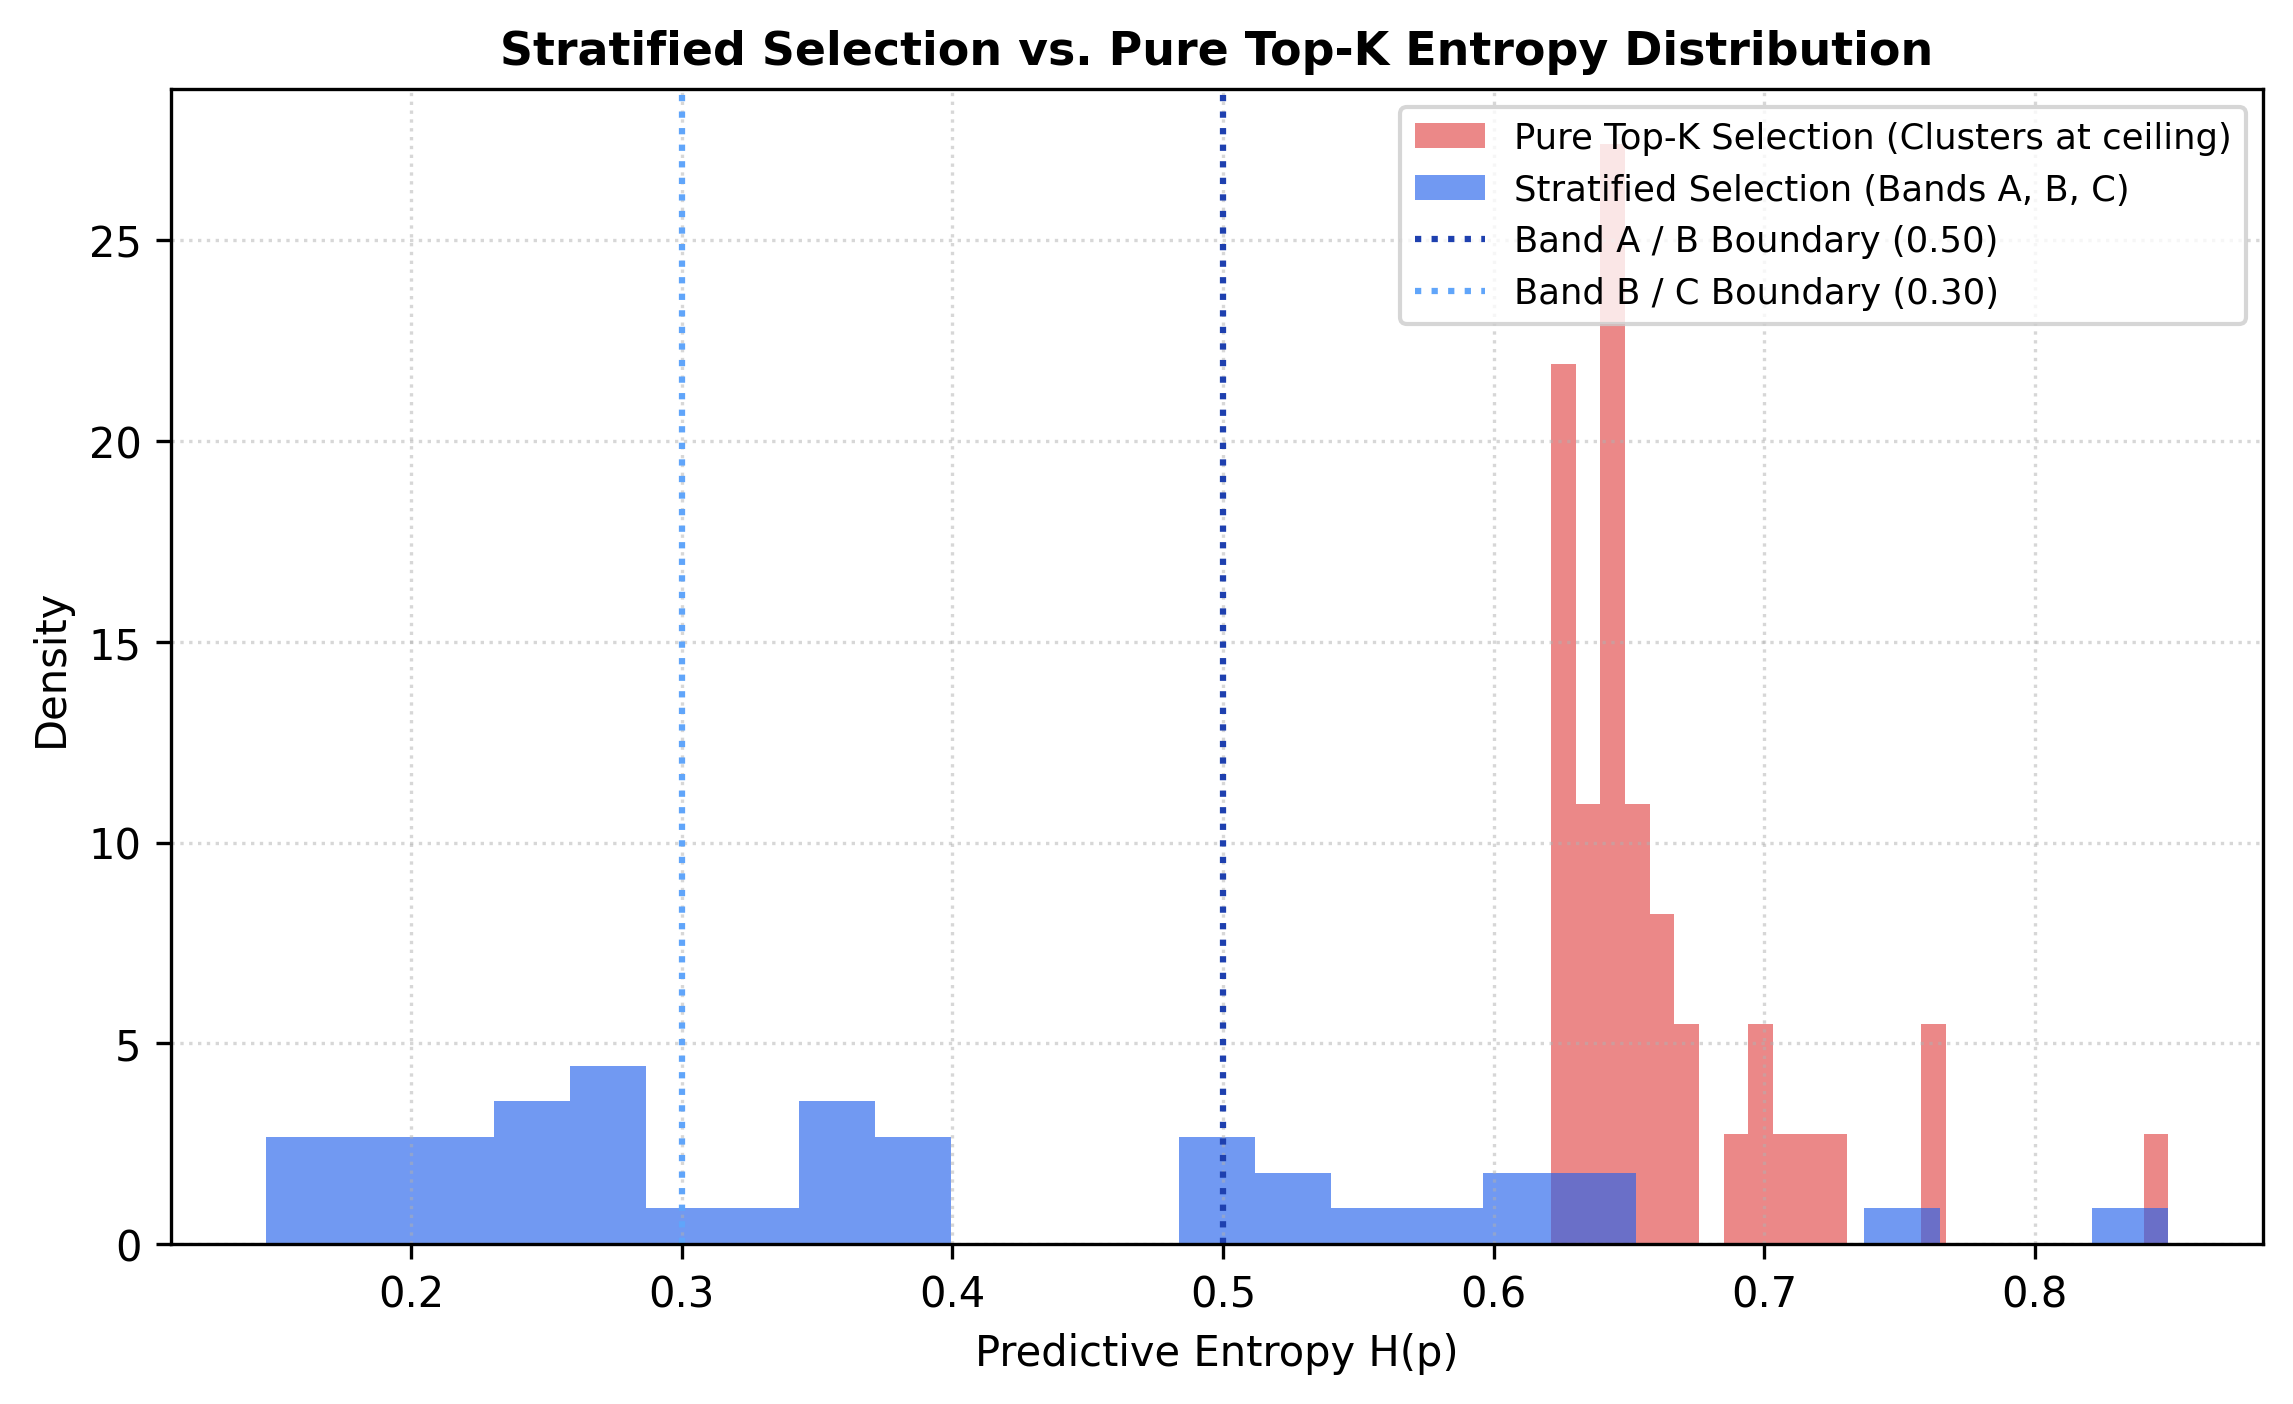

In [9]:
from src.active_learning.selector import StratifiedSampler, TopKSampler, RandomSampler
from src.active_learning.visualize import plot_stratified_vs_topk

stratified_sampler = StratifiedSampler(random_seed=SEED)
topk_sampler = TopKSampler()
random_sampler = RandomSampler(random_seed=SEED)

sample_budget = 40
stratified_sample = stratified_sampler.select(pool_df, budget=sample_budget)
topk_sample = topk_sampler.select(pool_df, budget=sample_budget)

topk_fig_path = os.path.join(OUTPUT_DIR, "figures", "stratified_vs_topk.png")
plot_stratified_vs_topk(stratified_sample, topk_sample, save_path=topk_fig_path)

from IPython.display import Image, display
display(Image(filename=topk_fig_path))

[FIGURE] Saved Uncertainty Overlay inspection to: outputs/active_learning\figures\uncertainty_overlay.png


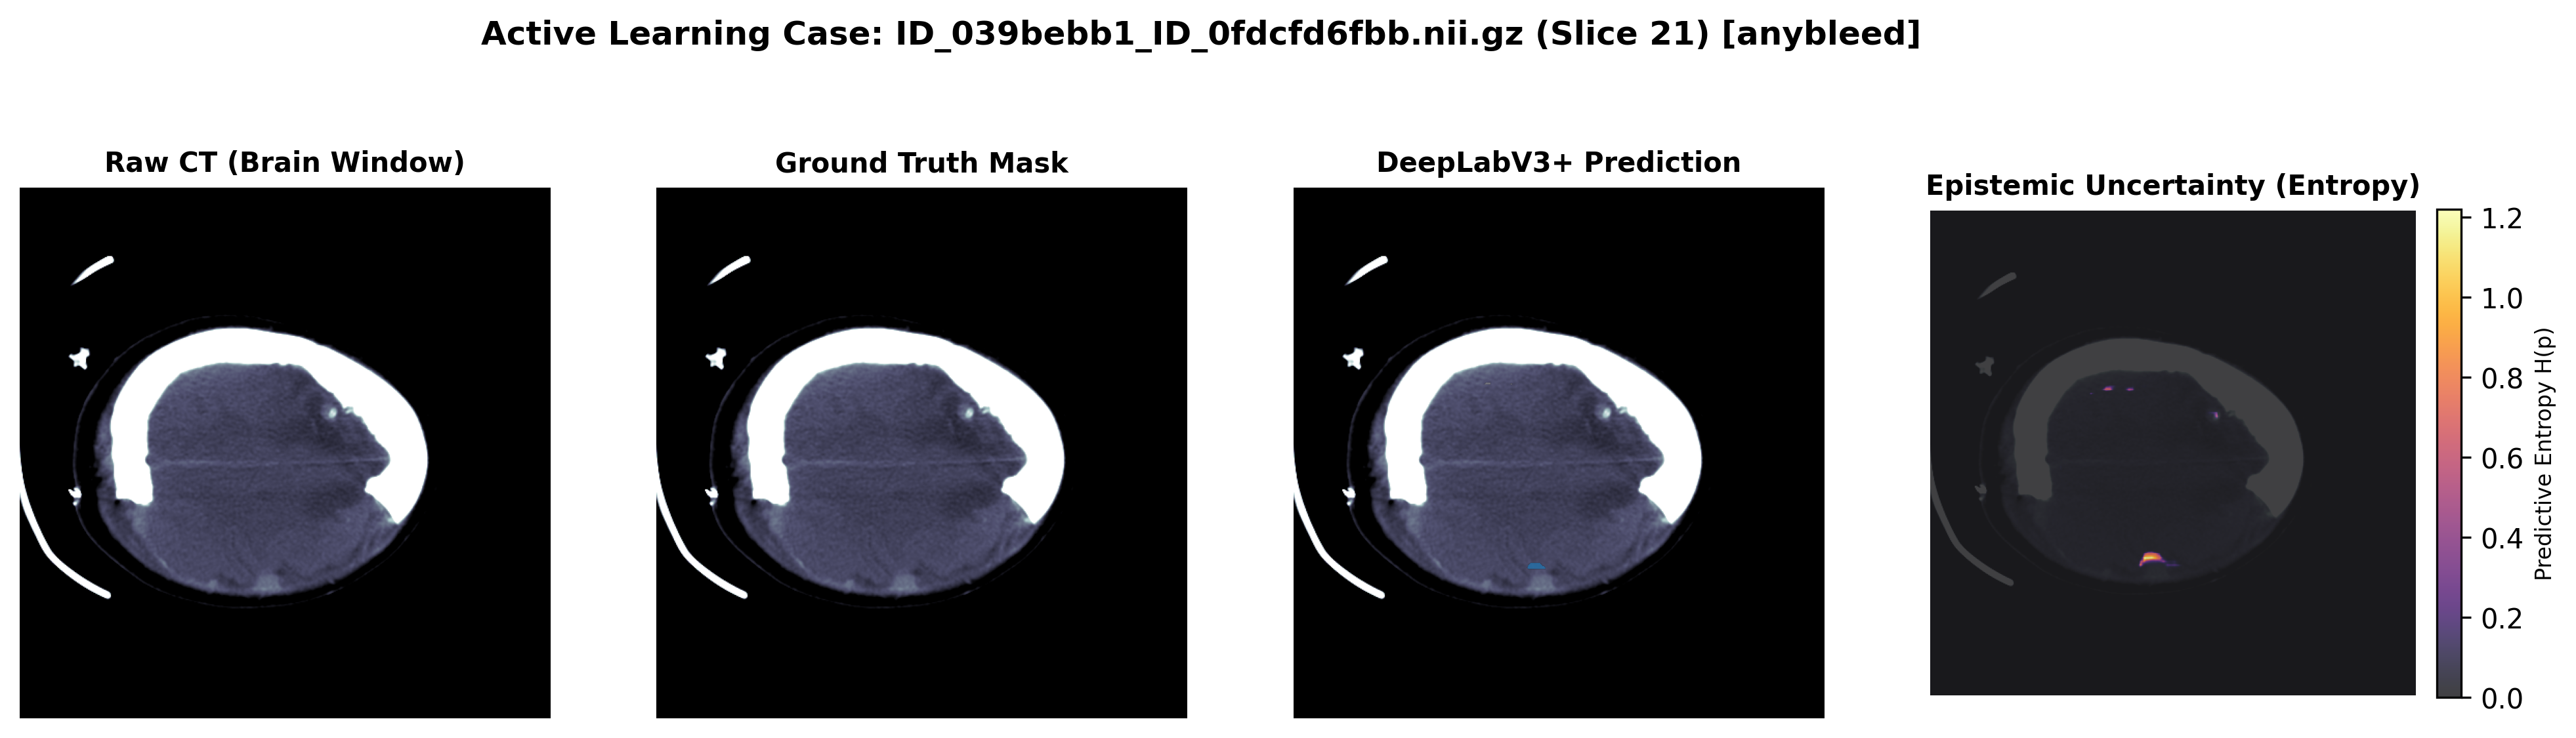

In [10]:
from src.active_learning.visualize import plot_uncertainty_overlay
from src.data.dataset import BrainCT25DDataset
from src.data.transforms import CTTransform

top_candidate = pool_df.sort_values(by="mean_fg_entropy", ascending=False).iloc[0]
top_fname = str(top_candidate["filename"])
top_sidx = int(top_candidate["slice_idx"])
top_cat = top_candidate.get("category", "")

overlay_fig_path = os.path.join(OUTPUT_DIR, "figures", "uncertainty_overlay.png")
overlay_rendered = False

# Check if available in pool_scorer dataset
if hasattr(pool_scorer, "dataset") and pool_scorer.dataset is not None:
    idx = pool_scorer.dataset.find_slice_index(top_fname, top_sidx) if hasattr(pool_scorer.dataset, "find_slice_index") else None
    if idx is not None:
        item = pool_scorer.dataset[idx]
        img = item[0] if isinstance(item, tuple) else item
        img_tensor = img.unsqueeze(0).to(device)
        with torch.no_grad():
            res = scorer.score_batch(img_tensor)
        ct_slice = img[1, :, :].cpu().numpy()
        pred_slice = res["pred_masks"][0].cpu().numpy()
        entropy_slice = res["entropy_map"][0].cpu().numpy()
        gt_slice = np.zeros_like(pred_slice)

        plot_uncertainty_overlay(
            ct_image=ct_slice,
            ground_truth=gt_slice,
            pred_mask=pred_slice,
            entropy_map=entropy_slice,
            slice_meta={"filename": top_fname, "slice_idx": top_sidx, "category": top_cat},
            save_path=overlay_fig_path,
        )
        overlay_rendered = True

if not overlay_rendered and os.path.exists("data_splits/dev_manifest.csv"):
    dev_dataset = BrainCT25DDataset(
        manifest_csv="data_splits/dev_manifest.csv",
        dataset_dir=DATASET_DIR,
        transform=CTTransform(is_training=False),
        cache_capacity=4,
    )
    for img, mask, meta in dev_dataset:
        if meta["filename"] == top_fname and meta["slice_idx"] == top_sidx:
            img_tensor = img.unsqueeze(0).to(device)
            with torch.no_grad():
                res = scorer.score_batch(img_tensor)
            ct_slice = img[1, :, :].cpu().numpy()
            gt_slice = mask.cpu().numpy()
            pred_slice = res["pred_masks"][0].cpu().numpy()
            entropy_slice = res["entropy_map"][0].cpu().numpy()

            plot_uncertainty_overlay(
                ct_image=ct_slice,
                ground_truth=gt_slice,
                pred_mask=pred_slice,
                entropy_map=entropy_slice,
                slice_meta={"filename": top_fname, "slice_idx": top_sidx, "category": top_cat},
                save_path=overlay_fig_path,
            )
            break

display(Image(filename=overlay_fig_path))

In [12]:
from src.active_learning.loop import ActiveLearningManager

manager = ActiveLearningManager(
    base_checkpoint_path=CHECKPOINT_PATH,
    dataset_dir=DATASET_DIR,
    train_manifest="data_splits/train_manifest.csv",
    train_slices="data_splits/train_slices.csv",
    val_manifest="data_splits/val_manifest.csv",
    output_dir=OUTPUT_DIR,
    device=device,
    buffer_size=100,
    fine_tune_epochs=2,
    batch_size=4,
    fine_tune_lr=1e-5,
)

history_csv = os.path.join(OUTPUT_DIR, "active_learning_history.csv")
if os.path.exists(history_csv):
    print(f"[CACHE] Loading benchmark history from {history_csv}")
    history_df = pd.read_csv(history_csv)
else:
    print(f"[BENCHMARK] Executing Active Learning vs Random Selection Benchmark...")
    history_df = manager.run_benchmark(
        pool_df=pool_df,
        rounds=2,
        budget_per_round=50,
    )

print("=" * 80)
print("  ACTIVE LEARNING BENCHMARK SUMMARY TABLE")
print("=" * 80)
display_cols = ["round", "strategy", "total_annotated_slices", "macro_dice", "edh_dice", "iph_dice", "ivh_dice"]
print(history_df[display_cols].to_string(index=False))
print("=" * 80)

[BUFFER] Prepared anti-forgetting buffer set with 100 slices (60 rare lesion slices).
[CACHE] Loading benchmark history from outputs/active_learning\active_learning_history.csv
  ACTIVE LEARNING BENCHMARK SUMMARY TABLE
 round                     strategy  total_annotated_slices  macro_dice  edh_dice  iph_dice  ivh_dice
     0 Active Learning (Stratified)                       0    0.446107  0.003382  0.798205  0.648917
     0   Random Selection (Control)                       0    0.446107  0.003382  0.798205  0.648917
     1 Active Learning (Stratified)                      10    0.452878  0.008639  0.796476  0.652861
     1   Random Selection (Control)                      10    0.453482  0.006027  0.799237  0.654541


[FIGURE] Saved Label-Efficiency Two-Curve figure to: outputs/active_learning\figures\label_efficiency_curves.png


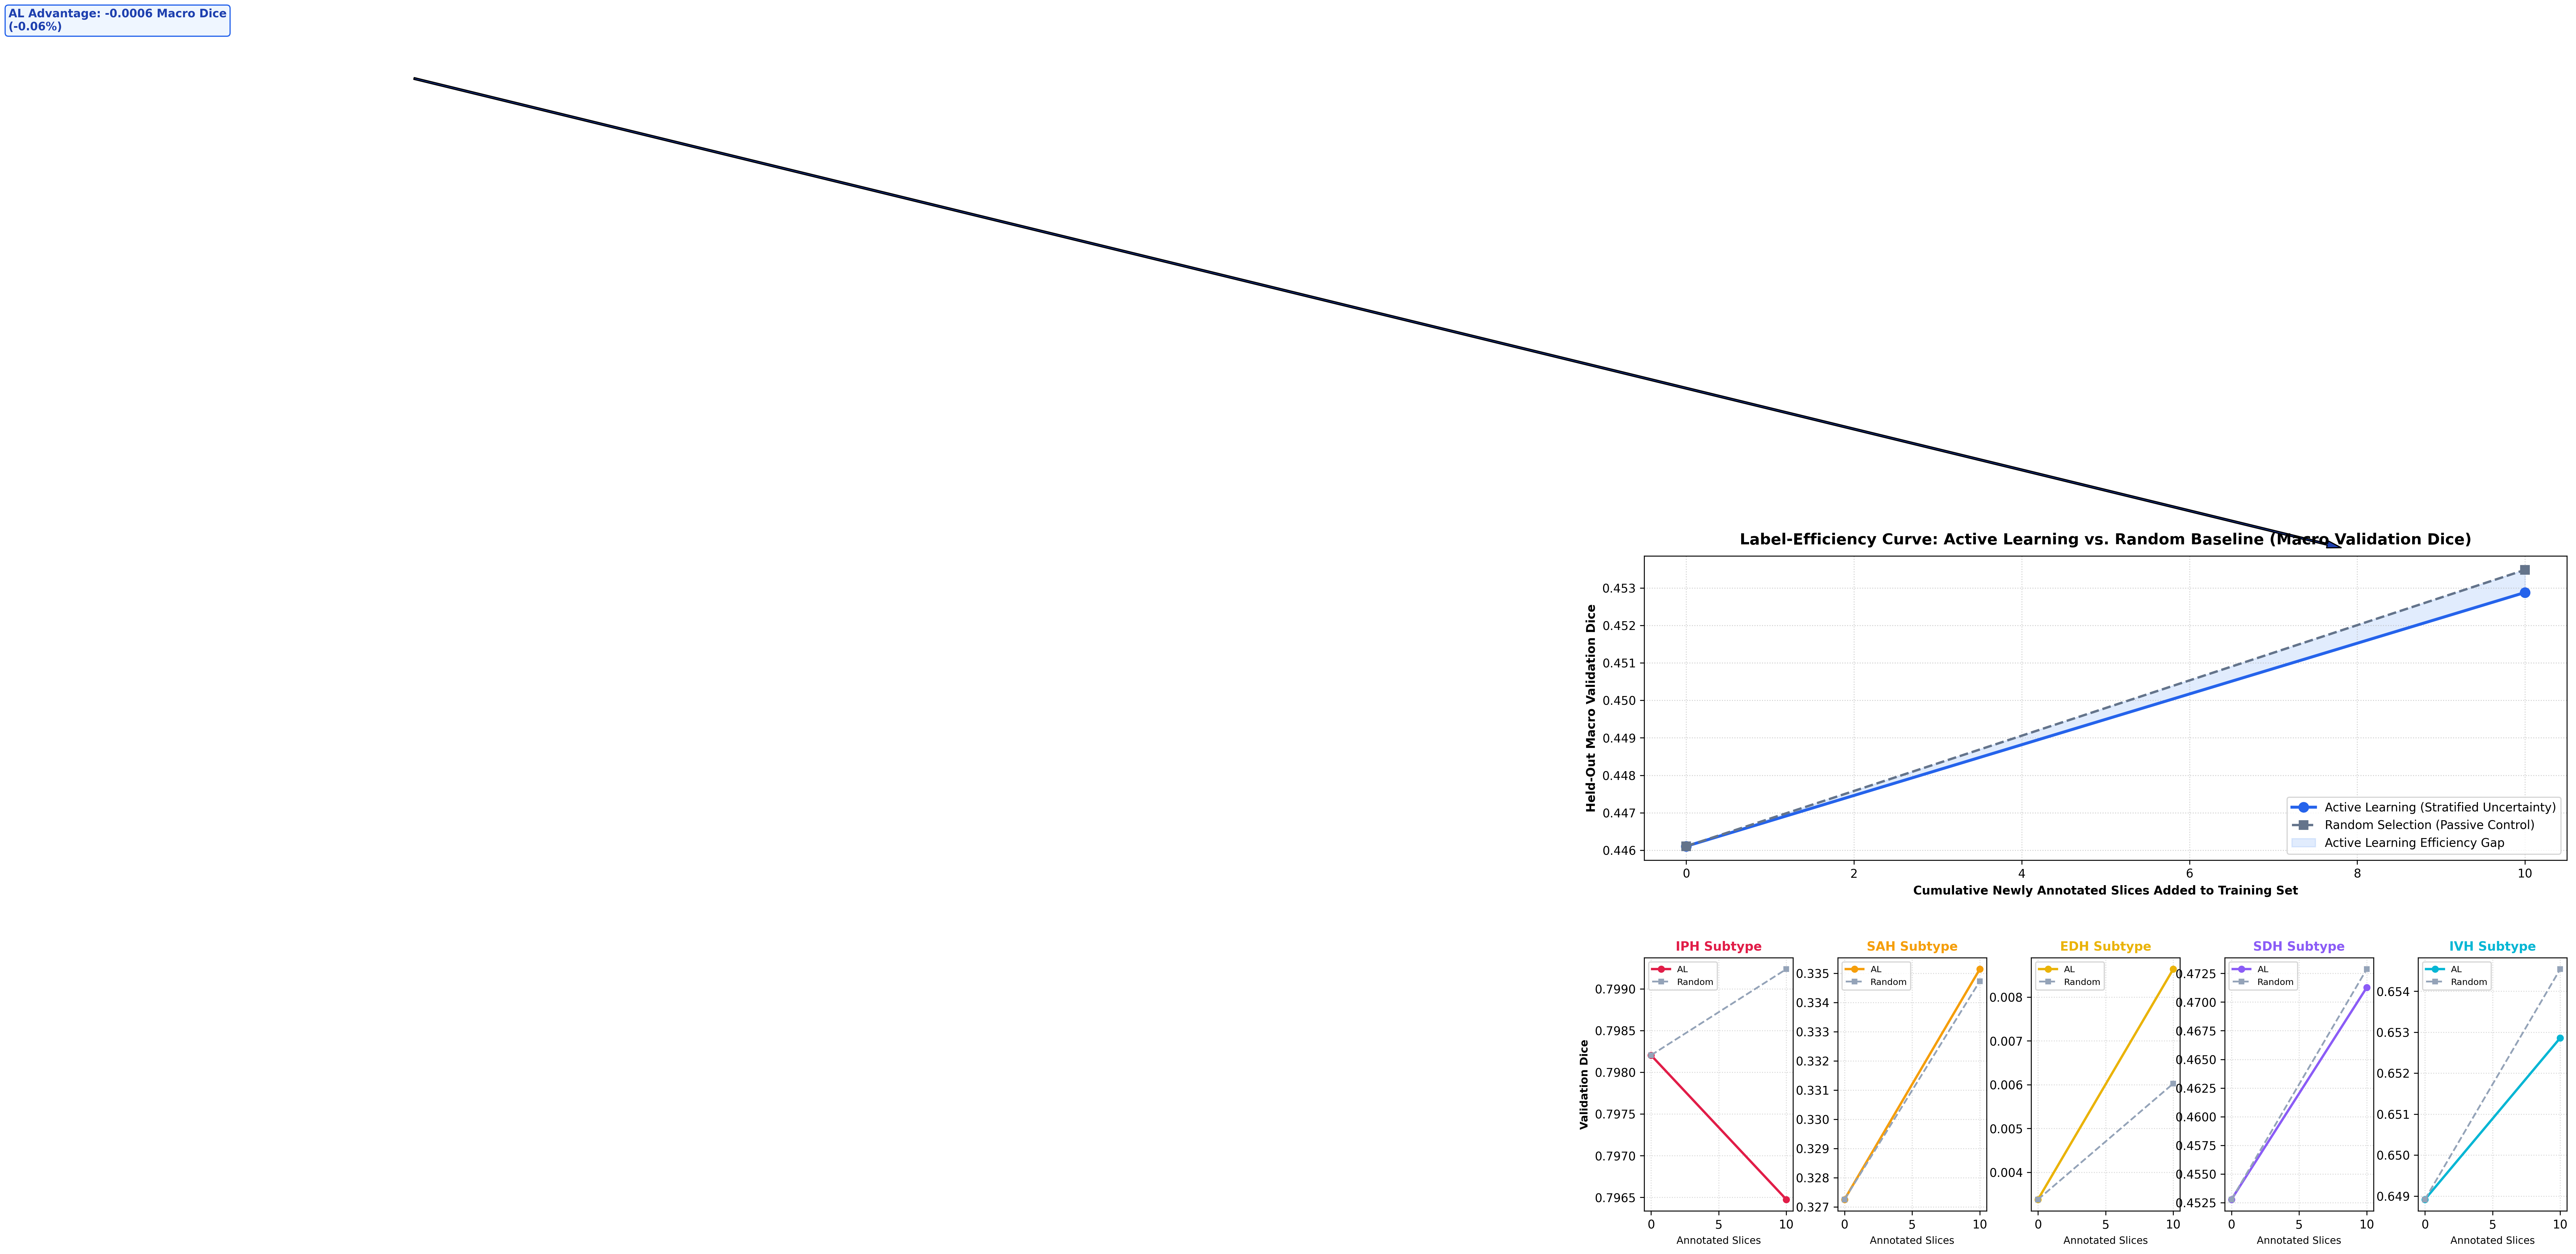

In [13]:
from src.active_learning.visualize import plot_label_efficiency_curves

curves_fig_path = os.path.join(OUTPUT_DIR, "figures", "label_efficiency_curves.png")
plot_label_efficiency_curves(history_df, save_path=curves_fig_path)
display(Image(filename=curves_fig_path))

[FIGURE] Saved Entropy Compression figure to: outputs/active_learning\figures\entropy_drift.png


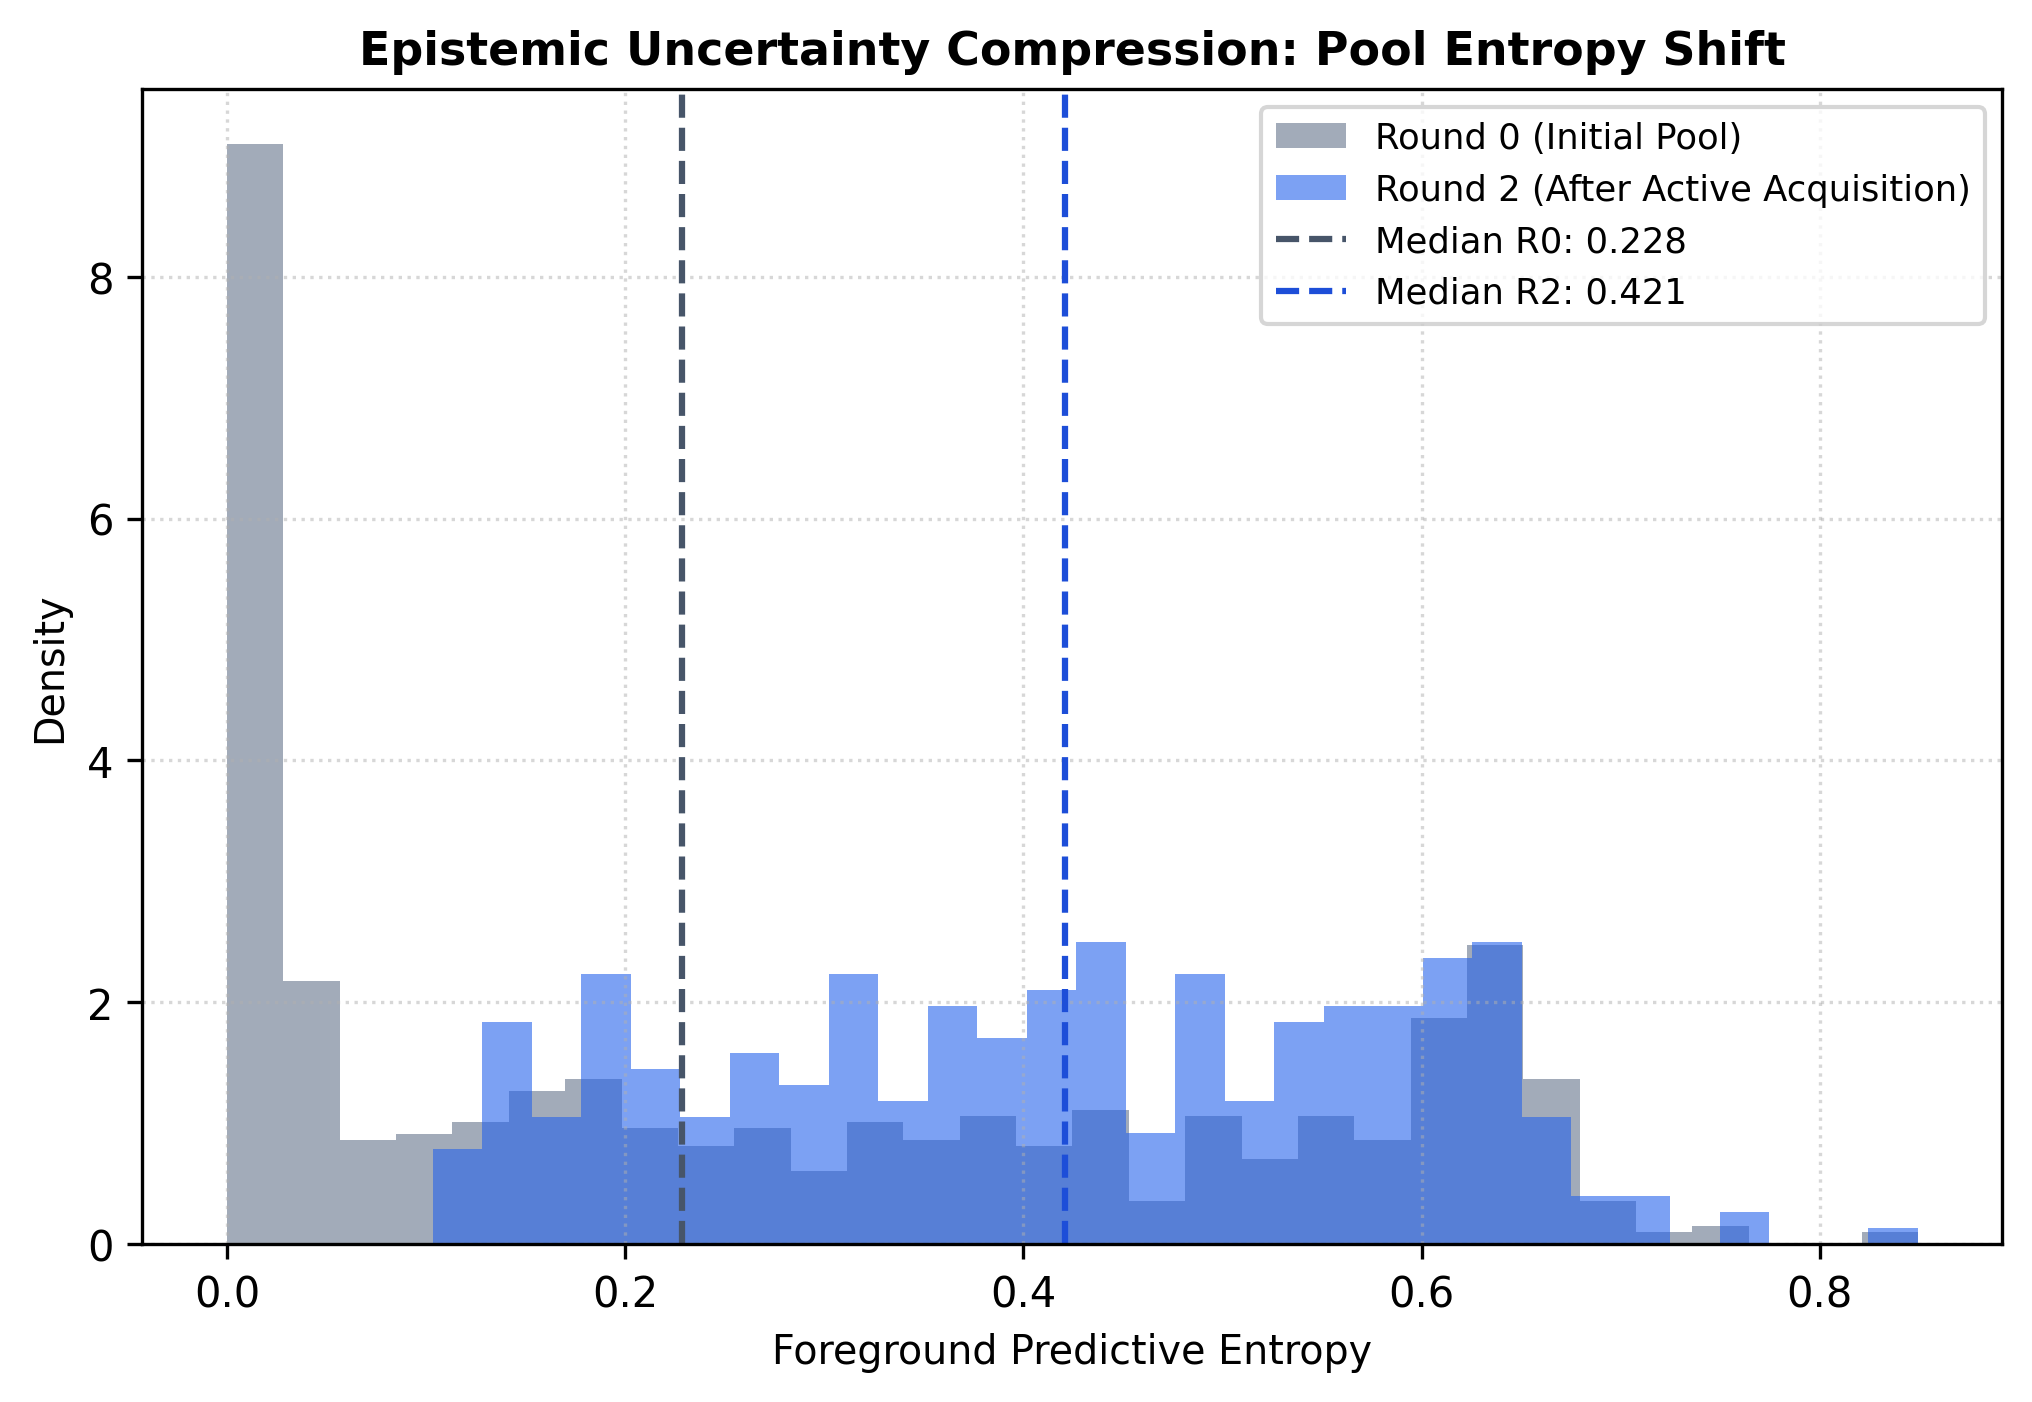

In [14]:
from src.active_learning.visualize import plot_entropy_drift

drift_fig_path = os.path.join(OUTPUT_DIR, "figures", "entropy_drift.png")
plot_entropy_drift(pool_df, pool_df[pool_df["eligible_candidate"]], save_path=drift_fig_path)
display(Image(filename=drift_fig_path))